# Guía 6 — Parte I: Radiación electromagnética

**Electromagnetismo Intermedio · Universidad de Valparaíso · 2026**

Este cuaderno acompaña los **Problemas 1–4** de la Guía 6. La idea no es repetir las derivaciones analíticas, sino *ver* la física que hay detrás de ellas:

| Problema | Qué se simula | Idea física central |
|---|---|---|
| 1 | Carga en órbita elíptica, campo en el eje, polarización en todas las direcciones | Solo radia la aceleración **transversal**; la forma de la órbita fija la polarización |
| 2 | Patrón $\sin^2\alpha$ para una aceleración oblicua | El patrón es geométrico: proyección de $\mathbf{a}$ perpendicular a $\hat{n}$ |
| 3 | Dipolo de Hertz: zonas cercana/lejana, líneas de campo que se desprenden, ley $\omega^4$ | Cómo nace la radiación a partir de un campo cuasiestático |
| 4 | Distribución angular relativista para $\mathbf{a}\parallel\mathbf{v}$ y $\mathbf{a}\perp\mathbf{v}$ | Efecto faro, factores $\gamma^6$ y $\gamma^4$ |

**Convenciones.** Usamos las de la guía (SI, $\eta_{\mu\nu}=\mathrm{diag}(1,-1,-1,-1)$). En los cálculos numéricos tomamos unidades adimensionales ($c=1$, $q/4\pi\varepsilon_0=1$, y las escalas propias de cada problema iguales a 1); cada gráfico indica en qué unidades está la cantidad graficada.

Todas las figuras se guardan en `figuras/`. Las funciones comunes (tensor $F$, boosts, Liénard–Wiechert, integración en la esfera) están en `../em_utils.py`, compartido por todas las guías.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation
from matplotlib.patches import FancyArrowPatch
from IPython.display import Image, display

import sys, os
sys.path.insert(0, os.path.abspath('..'))   # em_utils.py está en la raíz del repositorio
import em_utils as u
u.estilo()
C = u.COLORES

---
## Problema 1 — Radiación de una órbita elíptica

La carga sigue $\mathbf{r}_q(t)=b\cos\omega t\,\hat{x}+\tfrac b2\sin\omega t\,\hat{y}$, de modo que

$$\mathbf{a}=-\omega^2\mathbf{r}_q .$$

Es un **oscilador armónico isótropo**: dos osciladores lineales perpendiculares, en cuadratura y con amplitudes $b$ y $b/2$. Para un observador lejano en $\hat{n}$, el campo radiativo es

$$\mathbf{E}_{\rm rad}=\frac{q}{4\pi\varepsilon_0c^2R}\,\hat{n}\times(\hat{n}\times\mathbf{a}(t_r)) = -\frac{q}{4\pi\varepsilon_0c^2R}\,\mathbf{a}_\perp(t_r),$$

y solo importa la **parte de la aceleración perpendicular a la línea de visión**. En el eje $+z$ toda la aceleración es transversal, así que $\mathbf{E}_{\rm rad}\propto-\mathbf{a}$ recorre la misma elipse que la carga: **polarización elíptica**.

En las simulaciones tomamos $b=\omega=1$. Medimos $\mathbf{E}$ en unidades de $qb\omega^2/(4\pi\varepsilon_0c^2R)$ y $dP/d\Omega$ en unidades de

$$P_0\equiv\frac{q^2b^2\omega^4}{16\pi^2\varepsilon_0c^3}.$$

In [2]:
b, w = 1.0, 1.0
T = 2*np.pi/w

def orbita(t, eps=0.5):
    # eps = razón de semiejes (0.5 = elipse de la guía, 1 = círculo)
    t = np.asarray(t, float)
    r = np.stack([b*np.cos(w*t), eps*b*np.sin(w*t), 0*t], -1)
    v = np.stack([-b*w*np.sin(w*t), eps*b*w*np.cos(w*t), 0*t], -1)
    a = -w**2 * r
    return r, v, a

def E_rad(n, a):
    # n x (n x a) = n (n·a) - a   (unidades q/(4 pi eps0 c^2 R) = 1)
    n = np.asarray(n, float)
    return n*np.sum(n*a, -1, keepdims=True) - a

t = np.linspace(0, T, 801)
n_z = np.array([0, 0, 1.0])

r_e, v_e, a_e = orbita(t, 0.5)
r_c, v_c, a_c = orbita(t, 1.0)
E_e = E_rad(n_z, a_e);  B_e = np.cross(n_z, E_e)   # c B = n x E
E_c = E_rad(n_z, a_c)
dP_e = np.sum(E_e**2, -1)        # dP/dOmega en unidades de P0
dP_c = np.sum(E_c**2, -1)

prom_e = np.trapezoid(dP_e, t)/T
prom_c = np.trapezoid(dP_c, t)/T
print(f"<dP/dΩ> elipse  = {prom_e:.6f} P0   (analítico 5/8 = {5/8})")
print(f"<dP/dΩ> círculo = {prom_c:.6f} P0   (analítico 1)")
print(f"cociente        = {prom_e/prom_c:.6f}")

<dP/dΩ> elipse  = 0.625000 P0   (analítico 5/8 = 0.625)
<dP/dΩ> círculo = 1.000000 P0   (analítico 1)
cociente        = 0.625000


[guardado] figuras/P1_orbita_elipse_polarizacion.png


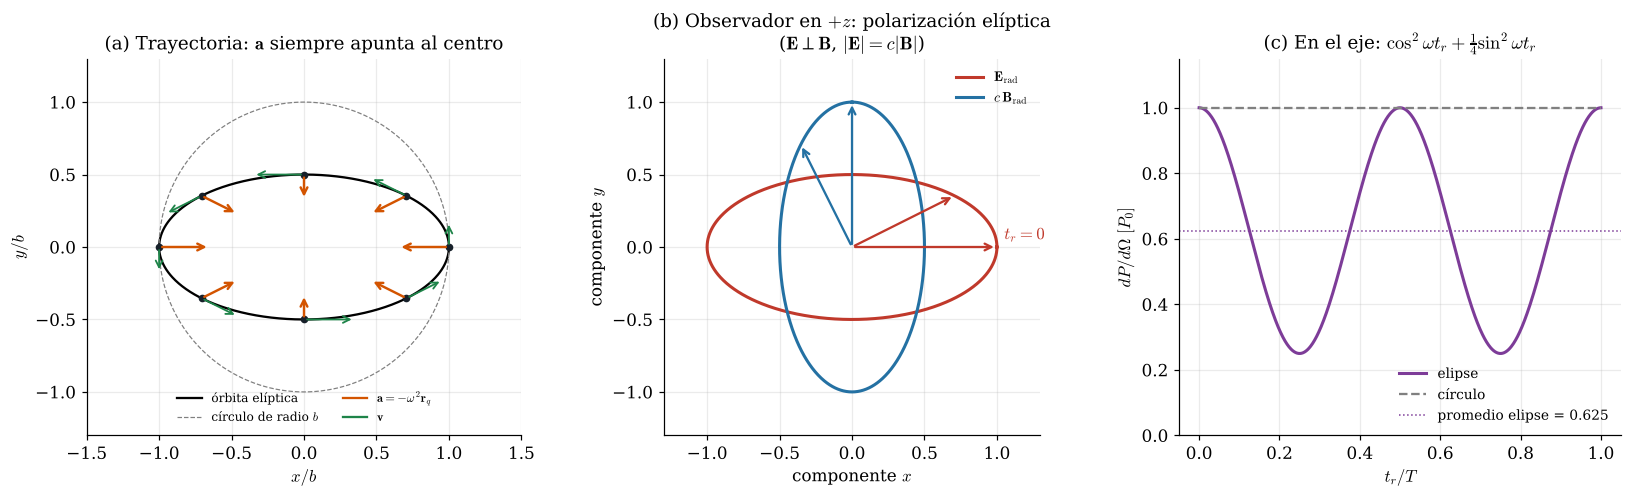

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))

# (a) órbita con v y a
A = ax[0]
A.plot(r_e[:, 0], r_e[:, 1], color='k', lw=1.5, label='órbita elíptica')
A.plot(r_c[:, 0], r_c[:, 1], color='gray', lw=0.8, ls='--', label='círculo de radio $b$')
for tk in np.linspace(0, T, 9)[:-1]:
    rk, vk, ak = [x[0] for x in orbita([tk], 0.5)]
    A.annotate('', xy=rk[:2] + 0.35*ak[:2], xytext=rk[:2],
               arrowprops=dict(arrowstyle='->', color=C['a'], lw=1.6))
    A.annotate('', xy=rk[:2] + 0.35*vk[:2], xytext=rk[:2],
               arrowprops=dict(arrowstyle='->', color=C['v'], lw=1.2))
    A.plot(*rk[:2], 'o', color=C['carga'], ms=4)
A.plot([], [], color=C['a'], label=r'$\mathbf{a}=-\omega^2\mathbf{r}_q$')
A.plot([], [], color=C['v'], label=r'$\mathbf{v}$')
A.set_aspect('equal'); A.set_xlim(-1.5, 1.5); A.set_ylim(-1.3, 1.3)
A.set_xlabel('$x/b$'); A.set_ylabel('$y/b$')
A.set_title('(a) Trayectoria: $\\mathbf{a}$ siempre apunta al centro')
A.legend(loc='lower center', fontsize=8, ncol=2)

# (b) polarización en el eje z
A = ax[1]
A.plot(E_e[:, 0], E_e[:, 1], color=C['E'], lw=2, label=r'$\mathbf{E}_{\rm rad}$')
A.plot(B_e[:, 0], B_e[:, 1], color=C['B'], lw=2, label=r'$c\,\mathbf{B}_{\rm rad}$')
for idx in [0, 100]:
    A.annotate('', xy=E_e[idx, :2], xytext=(0, 0), arrowprops=dict(arrowstyle='->', color=C['E'], lw=1.5))
    A.annotate('', xy=B_e[idx, :2], xytext=(0, 0), arrowprops=dict(arrowstyle='->', color=C['B'], lw=1.5))
A.text(E_e[0, 0]+0.05, 0.05, '$t_r=0$', color=C['E'])
A.set_aspect('equal'); A.set_xlim(-1.3, 1.3); A.set_ylim(-1.3, 1.3)
A.set_xlabel('componente $x$'); A.set_ylabel('componente $y$')
A.set_title('(b) Observador en $+z$: polarización elíptica\n($\\mathbf{E}\\perp\\mathbf{B}$, $|\\mathbf{E}|=c|\\mathbf{B}|$)')
A.legend(loc='upper right', fontsize=9)

# (c) potencia angular en función del tiempo
A = ax[2]
A.plot(t/T, dP_e, color=C['S'], lw=2, label='elipse')
A.plot(t/T, dP_c, color='gray', lw=1.5, ls='--', label='círculo')
A.axhline(prom_e, color=C['S'], lw=1, ls=':', label=f'promedio elipse = {prom_e:.3f}')
A.set_xlabel('$t_r/T$'); A.set_ylabel(r'$dP/d\Omega\;[P_0]$')
A.set_ylim(0, 1.15)
A.set_title('(c) En el eje: $\\cos^2\\omega t_r+\\frac{1}{4}\\sin^2\\omega t_r$')
A.legend(fontsize=9, loc='lower right')

fig.tight_layout()
u.guardar(fig, 'P1_orbita_elipse_polarizacion')
plt.show()

**Lectura de la figura.**

- (a) Como $\mathbf{a}=-\omega^2\mathbf{r}_q$, la aceleración es máxima en los extremos del eje mayor y mínima (la mitad) en los del eje menor.
- (b) El vector $\mathbf{E}_{\rm rad}$ recorre una elipse 2:1 y $c\mathbf{B}_{\rm rad}$ la misma elipse girada $90^\circ$: localmente es una onda plana con polarización elíptica.
- (c) $dP/d\Omega$ **no** es constante. Oscila con período $T/2$ (dos máximos por vuelta) entre $P_0$ y $P_0/4$. El promedio es $5/8$ del caso circular, en el que $|\mathbf{a}|$ no cambia y la potencia es constante.

### Animación: el observador ve el pasado

El observador en $z=R$ recibe a tiempo $t$ lo que la carga emitió en $t_r=t-R/c$. En la animación tomamos $R/c=T/4$ para que el retraso se vea. La carga "fantasma" (gris) es la posición **actual**; la negra es la posición **retardada**, que es la que determina el campo medido.

In [4]:
retraso = T/4                    # R/c
frames = 72
ts = np.linspace(0, T, frames, endpoint=False) + retraso

fig, (a1, a2) = plt.subplots(1, 2, figsize=(9.5, 4.4))
for A in (a1, a2):
    A.set_aspect('equal'); A.set_xlim(-1.4, 1.4); A.set_ylim(-1.4, 1.4)
a1.plot(r_e[:, 0], r_e[:, 1], color='k', lw=0.8)
a1.set_title('Carga (vista desde $+z$)'); a1.set_xlabel('$x/b$'); a1.set_ylabel('$y/b$')
a2.plot(E_e[:, 0], E_e[:, 1], color=C['E'], lw=0.8, alpha=0.3)
a2.set_title('Campo medido en $z=R$'); a2.set_xlabel('$E_x$'); a2.set_ylabel('$E_y$')

p_act, = a1.plot([], [], 'o', color='0.7', ms=9, label='posición actual $t$')
p_ret, = a1.plot([], [], 'o', color=C['carga'], ms=9, label='posición retardada $t_r$')
flecha_a = a1.annotate('', xy=(0, 0), xytext=(0, 0), arrowprops=dict(arrowstyle='->', color=C['a'], lw=2))
a1.legend(loc='lower center', fontsize=8)
flechaE = a2.annotate('', xy=(0, 0), xytext=(0, 0), arrowprops=dict(arrowstyle='->', color=C['E'], lw=2.5))
flechaB = a2.annotate('', xy=(0, 0), xytext=(0, 0), arrowprops=dict(arrowstyle='->', color=C['B'], lw=2))
txt = a2.text(-1.3, 1.2, '', fontsize=10)
a2.text(0.35, -1.25, r'rojo: $\mathbf{E}$, azul: $c\mathbf{B}$', fontsize=9)

def actualizar(i):
    tt = ts[i]; tr = tt - retraso
    ra, _, _ = [x[0] for x in orbita([tt], 0.5)]
    rr, _, ar = [x[0] for x in orbita([tr], 0.5)]
    Er = E_rad(n_z, ar); Br = np.cross(n_z, Er)
    p_act.set_data([ra[0]], [ra[1]]); p_ret.set_data([rr[0]], [rr[1]])
    flecha_a.xy = rr[:2] + 0.4*ar[:2]; flecha_a.set_position(rr[:2])
    flechaE.xy = Er[:2]; flechaE.set_position((0, 0))
    flechaB.xy = Br[:2]; flechaB.set_position((0, 0))
    txt.set_text(f'$t/T={tt/T:.2f}$,  $dP/d\\Omega={Er@Er:.2f}\\,P_0$')
    return p_act, p_ret, flecha_a, flechaE, flechaB, txt

anim = animation.FuncAnimation(fig, actualizar, frames=frames, blit=False)
u.guardar_gif(anim, 'P1_animacion_retardo_polarizacion', fps=18)
plt.close(fig)
# la animación se muestra en la celda siguiente (figuras/P1_animacion_retardo_polarizacion.gif)

[guardado] figuras/P1_animacion_retardo_polarizacion.gif  (0.43 MB)


![animación](figuras/P1_animacion_retardo_polarizacion.gif)

### Más allá del eje: la polarización depende de la dirección

El problema pide solo $\hat{n}=\hat{z}$, pero vale la pena mirar en **todas** las direcciones. Para cada $\hat{n}=(\theta,\phi)$ calculamos $\mathbf{E}_{\rm rad}(t)$ durante un período y lo proyectamos en la base transversal $(\hat\theta,\hat\phi)$:

- **Sobre los polos** ($\theta=0,\pi$): elipse 2:1 (lo que calculamos analíticamente).
- **En el plano de la órbita** ($\theta=90^\circ$): una de las dos componentes de $\mathbf{a}$ es longitudinal y no radia. La elipse colapsa a un segmento: **polarización lineal**.
- **Promedio temporal**: los dos dipolos están en cuadratura ($\langle\cos\omega t\sin\omega t\rangle=0$) y sus potencias se suman,
$$\Big\langle\frac{dP}{d\Omega}\Big\rangle=\frac{P_0}{2}\Big[(1-n_x^2)+\tfrac14(1-n_y^2)\Big].$$

máx |numérico - analítico| = 4.440892098500626e-16


[guardado] figuras/P1_mapa_polarizacion_direcciones.png


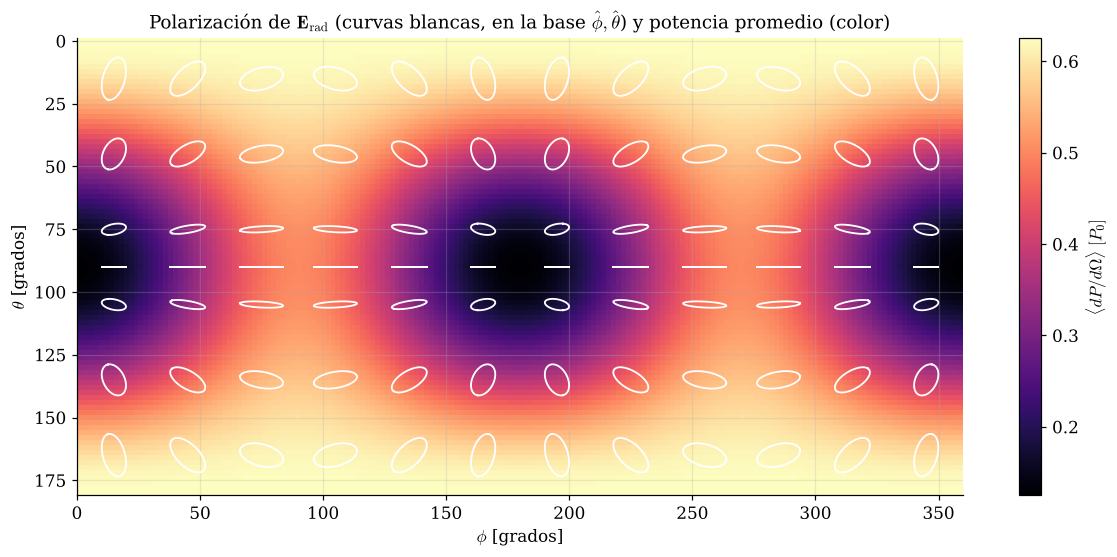

<P>/P0 = 5.235988   (5π/3 = 5.235988)
En SI: <P> = 5 q² b² ω⁴ / (48 π ε0 c³), igual a Larmor con <a²> = (5/8) b² ω⁴


In [5]:
tt = np.linspace(0, T, 200, endpoint=False)
_, _, a_T = orbita(tt, 0.5)

# fondo: <dP/dΩ> calculado promediando en el tiempo (sin usar la fórmula)
TH, PH, N = u.esfera(91, 181)
prom = np.zeros(TH.shape)
for ak in a_T[::4]:
    Ek = E_rad(N, ak)
    prom += np.sum(Ek**2, -1)
prom /= len(a_T[::4])
analitico = 0.5*((1 - N[..., 0]**2) + 0.25*(1 - N[..., 1]**2))
print('máx |numérico - analítico| =', np.abs(prom - analitico).max())

fig, ax = plt.subplots(figsize=(11, 5.2))
im = ax.pcolormesh(np.degrees(PH), np.degrees(TH), prom, cmap='magma', shading='auto')
plt.colorbar(im, ax=ax, label=r'$\langle dP/d\Omega\rangle\;[P_0]$')

escala = 9.0   # grados por unidad de campo
for th0 in np.radians([15, 45, 75, 90, 105, 135, 165]):
    for ph0 in np.radians(np.arange(0, 360, 30) + 15):
        n = np.array([np.sin(th0)*np.cos(ph0), np.sin(th0)*np.sin(ph0), np.cos(th0)])
        e_th = np.array([np.cos(th0)*np.cos(ph0), np.cos(th0)*np.sin(ph0), -np.sin(th0)])
        e_ph = np.array([-np.sin(ph0), np.cos(ph0), 0.0])
        Et = E_rad(n, a_T)
        Eth, Eph = Et @ e_th, Et @ e_ph
        ax.plot(np.degrees(ph0) + escala*Eph, np.degrees(th0) + escala*Eth, color='w', lw=1.2)
ax.invert_yaxis()
ax.set_xlabel(r'$\phi$ [grados]'); ax.set_ylabel(r'$\theta$ [grados]')
ax.set_title('Polarización de $\\mathbf{E}_{\\rm rad}$ (curvas blancas, en la base $\\hat\\phi,\\hat\\theta$) '
             'y potencia promedio (color)')
ax.set_xlim(0, 360)
fig.tight_layout()
u.guardar(fig, 'P1_mapa_polarizacion_direcciones')
plt.show()

P_tot = u.integrar_esfera(lambda n: 0.5*((1 - n[..., 0]**2) + 0.25*(1 - n[..., 1]**2)))
print(f"<P>/P0 = {P_tot:.6f}   (5π/3 = {5*np.pi/3:.6f})")
print("En SI: <P> = 5 q² b² ω⁴ / (48 π ε0 c³), igual a Larmor con <a²> = (5/8) b² ω⁴")

Las curvas blancas son **elipses de polarización**. Cerca de los polos son elipses 2:1 (la órbita vista desde arriba, rotada según $\phi$), en el ecuador ($\theta=90^\circ$) son segmentos rectos, y en medio son elipses cada vez más achatadas.

El color muestra la potencia promedio. Es **máxima en los polos** ($\frac58P_0$), donde ambos dipolos son transversales. Vale $\frac12P_0$ en $\pm\hat y$, donde solo el dipolo grande ($p_x$, amplitud $b$) es transversal. Es **mínima en $\pm\hat x$** ($\frac18P_0$), a lo largo del eje mayor, donde solo radia el dipolo pequeño ($p_y$, amplitud $b/2$).

El resultado total $\langle P\rangle=\frac{5\pi}{3}P_0$ coincide con Larmor, $\frac{q^2\langle a^2\rangle}{6\pi\varepsilon_0c^3}$ con $\langle a^2\rangle=\frac{5}{8} b^2\omega^4$. Es una buena consistencia: integrar la distribución angular reproduce la fórmula de potencia total.

---
## Problema 2 — Dirección de observación y patrón angular

Con $\mathbf{a}=a_0(\hat{x}+\hat{z})/\sqrt2$:

$$\frac{dP}{d\Omega}=\frac{q^2a_0^2}{16\pi^2\varepsilon_0c^3}\sin^2\alpha,\qquad |\hat{n}\times(\hat{n}\times\mathbf{a})|^2=a^2-(\hat{n}\cdot\mathbf{a})^2=a^2\sin^2\alpha .$$

Es la "dona" dipolar inclinada $45^\circ$ en el plano $xz$. Graficamos el patrón en 3D y como mapa $(\theta,\phi)$, y marcamos las tres direcciones del enunciado.

n = x:  sin²α = 0.500
n = y:  sin²α = 1.000
n = z:  sin²α = 0.500


∮ sin²α dΩ = 8.377580409572792  (8π/3 = 8.377580409572781 )


[guardado] figuras/P2_patron_angular_oblicuo.png


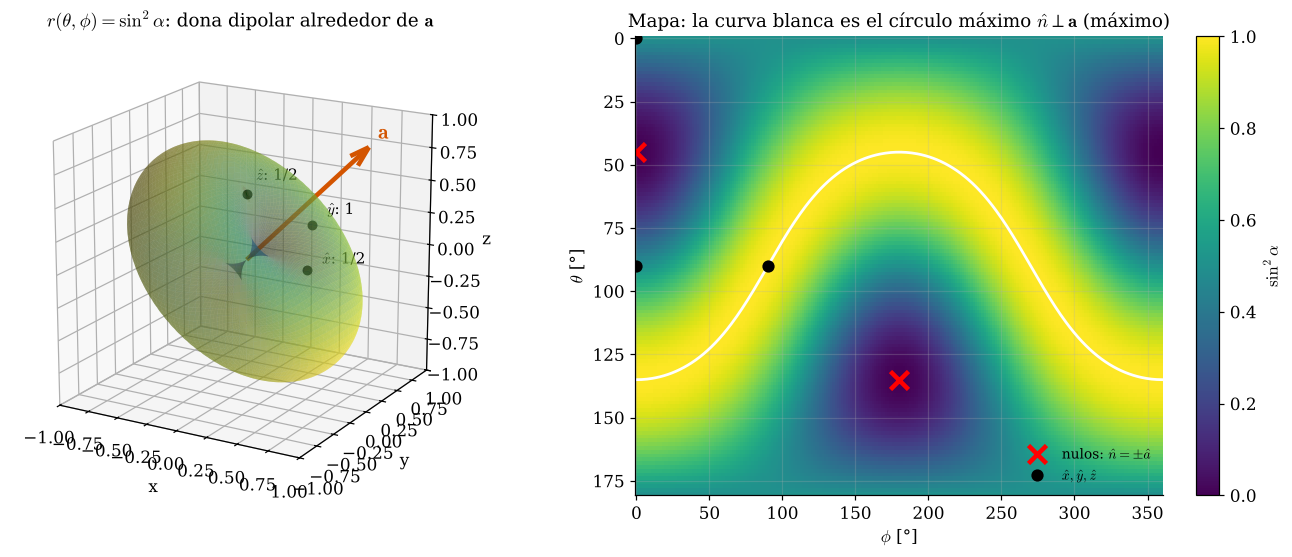

In [6]:
a_hat = np.array([1, 0, 1])/np.sqrt(2)
patron = lambda n: 1 - (n @ a_hat)**2          # sin^2(alpha), unidades q^2 a0^2/(16 pi^2 eps0 c^3)

for nombre, n in [('x', [1, 0, 0]), ('y', [0, 1, 0]), ('z', [0, 0, 1])]:
    print(f"n = {nombre}:  sin²α = {patron(np.array(n, float)):.3f}")
print("∮ sin²α dΩ =", u.integrar_esfera(patron), " (8π/3 =", 8*np.pi/3, ")")

TH, PH, N = u.esfera(121, 241)
Rr = patron(N)
fig = plt.figure(figsize=(13, 5.2))
A = fig.add_subplot(1, 2, 1, projection='3d')
X, Y, Z = (Rr[..., None]*N).transpose(2, 0, 1)
A.plot_surface(X, Y, Z, facecolors=plt.cm.viridis(Rr), rstride=2, cstride=2, linewidth=0, alpha=0.45)
A.quiver(0, 0, 0, *(1.4*a_hat), color=C['a'], lw=3, arrow_length_ratio=0.12)
A.text(*(1.5*a_hat), r'$\mathbf{a}$', color=C['a'], fontsize=14)
for vec, lab in [([1, 0, 0], r'$\hat{x}$: 1/2'), ([0, 1, 0], r'$\hat{y}$: 1'), ([0, 0, 1], r'$\hat{z}$: 1/2')]:
    vec = np.array(vec, float); rr = patron(vec)
    A.scatter(*(rr*vec), color='k', s=30); A.text(*(1.1*rr*vec + 0.05), lab, fontsize=10)
A.set_xlim(-1, 1); A.set_ylim(-1, 1); A.set_zlim(-1, 1)
A.set_box_aspect((1, 1, 1)); A.set_xlabel('x'); A.set_ylabel('y'); A.set_zlabel('z')
A.set_title(r'$r(\theta,\phi)=\sin^2\alpha$: dona dipolar alrededor de $\mathbf{a}$')
A.view_init(elev=18, azim=-60)

A = fig.add_subplot(1, 2, 2)
im = A.pcolormesh(np.degrees(PH), np.degrees(TH), Rr, cmap='viridis', shading='auto')
phc = np.linspace(0, 2*np.pi, 400)
A.plot(np.degrees(phc), np.degrees(np.arctan2(1, -np.cos(phc))), color='w', lw=1.8)
A.plot([0, 180], [45, 135], 'rx', ms=12, mew=3, label=r'nulos: $\hat{n}=\pm\hat{a}$')
A.plot([0, 90, 0], [90, 90, 0], 'ko', ms=7, label=r'$\hat{x},\hat{y},\hat{z}$')
A.invert_yaxis(); A.set_xlabel(r'$\phi$ [°]'); A.set_ylabel(r'$\theta$ [°]')
A.set_title('Mapa: la curva blanca es el círculo máximo $\\hat{n}\\perp\\mathbf{a}$ (máximo)')
plt.colorbar(im, ax=A, label=r'$\sin^2\alpha$'); A.legend(loc='lower right', fontsize=9)
fig.tight_layout()
u.guardar(fig, 'P2_patron_angular_oblicuo')
plt.show()

El patrón **no depende del sistema de ejes**: es simplemente $\sin^2$ del ángulo con $\mathbf{a}$. $\hat{x}$ y $\hat{z}$ forman $45^\circ$ con $\mathbf{a}$ y dan el mismo valor ($1/2$). $\hat{y}$ es perpendicular y está en el máximo. Los nulos están **a lo largo** de $\mathbf{a}$: un observador allí ve la carga moverse "hacia él y alejándose", sin desplazamiento transversal aparente, y una onda en el vacío no tiene componente longitudinal.

---
## Problema 3 — El dipolo armónico: cómo *nace* la radiación

En la guía solo se usó el campo lejano. Aquí miramos el **campo completo** de un dipolo $\mathbf{p}=p_0\cos\omega t\,\hat{z}$ (Jackson, ec. 9.18), con $k=\omega/c$:

$$E_r=\frac{p_0}{4\pi\varepsilon_0}\,2\cos\theta\,\mathrm{Re}\Big[\Big(\frac1{r^3}-\frac{ik}{r^2}\Big)e^{i(kr-\omega t)}\Big],\qquad
E_\theta=\frac{p_0}{4\pi\varepsilon_0}\,\sin\theta\,\mathrm{Re}\Big[\Big(\frac1{r^3}-\frac{ik}{r^2}-\frac{k^2}{r}\Big)e^{i(kr-\omega t)}\Big].$$

- Término $1/r^3$: el dipolo **electrostático**, que "sigue" a $\mathbf{p}(t)$ instantáneamente.
- Término $1/r^2$: término de inducción.
- Término $k^2/r$: el campo de **radiación** del problema, $E_\theta\propto\sin\theta\cos[\omega(t-r/c)]/r$.

### Escalas: zona cercana vs. zona de radiación

[guardado] figuras/P3_escalas_zona_cercana_lejana.png


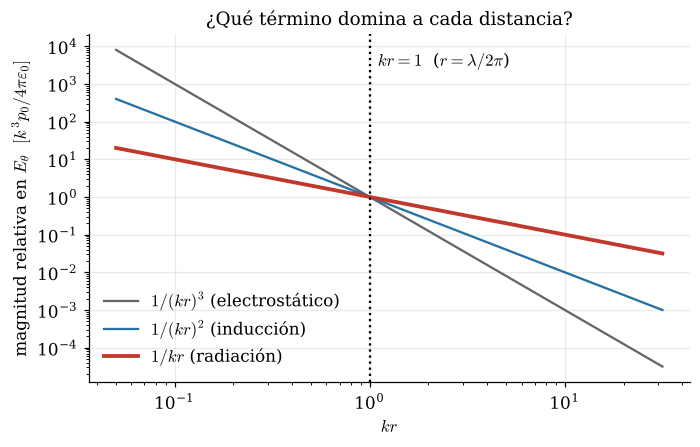

In [7]:
kr = np.logspace(-1.3, 1.5, 300)
fig, A = plt.subplots(figsize=(6.5, 4.2))
A.loglog(kr, kr**-3, label=r'$1/(kr)^3$ (electrostático)', color='0.4')
A.loglog(kr, kr**-2, label=r'$1/(kr)^2$ (inducción)', color=C['B'])
A.loglog(kr, kr**-1, label=r'$1/kr$ (radiación)', color=C['E'], lw=2.5)
A.axvline(1, color='k', ls=':'); A.text(1.1, 3e3, r'$kr=1$  ($r=\lambda/2\pi$)')
A.set_xlabel('$kr$'); A.set_ylabel(r'magnitud relativa en $E_\theta$  $[k^3p_0/4\pi\varepsilon_0]$')
A.set_title('¿Qué término domina a cada distancia?'); A.legend()
fig.tight_layout(); u.guardar(fig, 'P3_escalas_zona_cercana_lejana'); plt.show()

Para $kr\gg1$ domina el término $1/r$. Es el único cuya energía, $\propto r^2E^2$, llega al infinito: **eso es radiación**. Los otros dos almacenan energía que va y vuelve, sin escapar.

### Líneas de campo: los lazos que se desprenden

En una región sin cargas y con simetría azimutal, $\nabla\cdot\mathbf{E}=0$ permite escribir $\mathbf{E}=\nabla\times\big(\frac{\mathcal F}{r\sin\theta}\hat\phi\big)$, es decir

$$E_r=\frac{1}{r^2\sin\theta}\partial_\theta\mathcal F,\qquad E_\theta=-\frac{1}{r\sin\theta}\partial_r\mathcal F .$$

Así, $\mathbf{E}\cdot\nabla\mathcal F=\frac{\partial_\theta\mathcal F\,\partial_r\mathcal F}{r^2\sin\theta}-\frac{\partial_r\mathcal F\,\partial_\theta\mathcal F}{r^2\sin\theta}=0$: **las líneas de $\mathbf{E}$ son las curvas de nivel de $\mathcal F$**.

Para encontrar $\mathcal F$, proponemos $\mathcal F=\sin^2\theta\,f(r)\,e^{-i\omega t}$. De $E_r$: $\frac{2\sin\theta\cos\theta f}{r^2\sin\theta}=2\cos\theta\frac{f}{r^2}$, lo que exige $f=(\frac1r-ik)e^{ikr}$. Con eso, $-\frac{\sin\theta f'}{r}=\sin\theta\big(\frac1{r^3}-\frac{ik}{r^2}-\frac{k^2}{r}\big)e^{ikr}$ reproduce $E_\theta$ sin ajuste adicional. Entonces

$$\mathcal F(r,\theta,t)=\sin^2\theta\,\mathrm{Re}\Big[\Big(\frac1r-ik\Big)e^{i(kr-\omega t)}\Big]=\sin^2\theta\Big[\frac{\cos(kr-\omega t)}{r}+k\sin(kr-\omega t)\Big].$$

Antes de confiar en ella, **verificamos numéricamente** que $\mathbf{E}\cdot\nabla\mathcal F=0$ con los campos exactos.

In [8]:
k = 2*np.pi            # lambda = 1
wd = k                 # c = 1
def campos_dipolo(r, th, t):
    fase = np.exp(1j*(k*r - wd*t))
    Er = np.real(2*np.cos(th)*(1/r**3 - 1j*k/r**2)*fase)
    Et = np.real(np.sin(th)*(1/r**3 - 1j*k/r**2 - k**2/r)*fase)
    return Er, Et

def Fflujo(r, th, t):
    return np.sin(th)**2*(np.cos(k*r - wd*t)/r + k*np.sin(k*r - wd*t))

# verificación E·∇F = 0 en una malla (r, theta)
r1 = np.linspace(0.1, 2, 400); th1 = np.linspace(0.05, np.pi - 0.05, 300)
RR, TT = np.meshgrid(r1, th1, indexing='ij')
t0 = 0.13
Fv = Fflujo(RR, TT, t0)
dF_dr, dF_dth = np.gradient(Fv, r1, th1, edge_order=2)
Er, Et = campos_dipolo(RR, TT, t0)
grad_r, grad_th = dF_dr, dF_dth/RR            # componentes del gradiente en la base (r̂, θ̂)
cos_ang = (Er*grad_r + Et*grad_th)/(np.hypot(Er, Et)*np.hypot(grad_r, grad_th) + 1e-300)
print(f"mediana |cos(ángulo entre E y ∇F)| = {np.median(np.abs(cos_ang)):.2e}  -> E es tangente a las curvas F=cte")
# y la reconstrucción de E desde F:
Er_F = dF_dth/(RR**2*np.sin(TT)); Et_F = -dF_dr/(RR*np.sin(TT))
print("error relativo al reconstruir E desde F:",
      f"{np.linalg.norm(Er_F - Er)/np.linalg.norm(Er):.1e} (E_r), {np.linalg.norm(Et_F - Et)/np.linalg.norm(Et):.1e} (E_θ)")

mediana |cos(ángulo entre E y ∇F)| = 1.61e-05  -> E es tangente a las curvas F=cte
error relativo al reconstruir E desde F: 7.1e-05 (E_r), 3.4e-03 (E_θ)


[guardado] figuras/P3_lineas_campo_dipolo_hertz.png


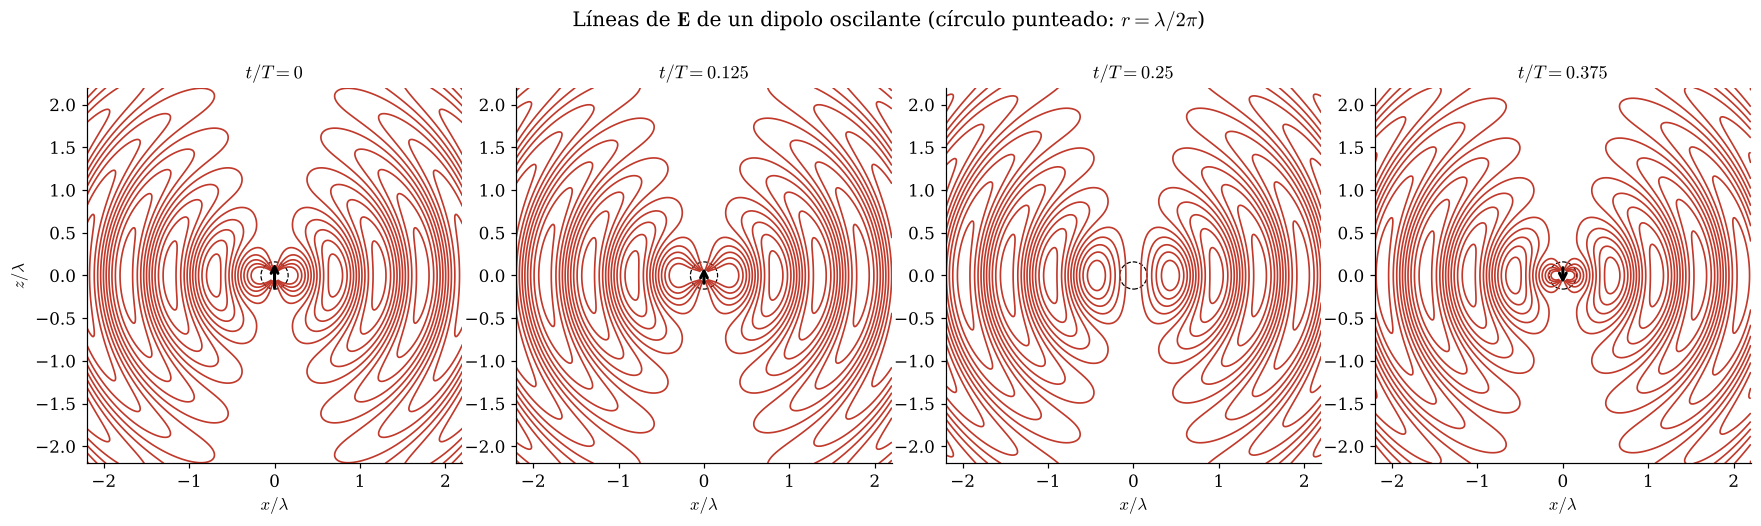

In [9]:
L = 2.2
x = np.linspace(-L, L, 500); z = np.linspace(-L, L, 500)
X, Z = np.meshgrid(x, z)
Rg = np.hypot(X, Z); THg = np.arctan2(np.abs(X), Z)
mask = Rg < 0.06
niveles = np.linspace(-0.9, 0.9, 10)*k

def dibujar(A, t):
    Fv = Fflujo(np.maximum(Rg, 1e-3), THg, t)
    Fv = np.where(mask, np.nan, Fv)
    A.contour(X, Z, Fv, levels=niveles, colors=[C['E']], linewidths=1.1, linestyles='solid')
    A.add_patch(plt.Circle((0, 0), 1/(2*np.pi), fill=False, ls='--', color='k', lw=0.8))
    pz = np.cos(wd*t)
    A.annotate('', xy=(0, 0.18*pz), xytext=(0, -0.18*pz), arrowprops=dict(arrowstyle='->', color='k', lw=2))
    A.set_aspect('equal'); A.set_xlim(-L, L); A.set_ylim(-L, L); A.grid(False)

fig, ax = plt.subplots(1, 4, figsize=(16, 4.4))
for A, tf in zip(ax, [0, 0.125, 0.25, 0.375]):
    dibujar(A, tf); A.set_title(f'$t/T={tf}$'); A.set_xlabel(r'$x/\lambda$')
ax[0].set_ylabel(r'$z/\lambda$')
fig.suptitle('Líneas de $\\mathbf{E}$ de un dipolo oscilante (círculo punteado: $r=\\lambda/2\\pi$)', y=1.02)
fig.tight_layout(); u.guardar(fig, 'P3_lineas_campo_dipolo_hertz'); plt.show()

In [10]:
fig, A = plt.subplots(figsize=(5.2, 5.2))
fr = 40
def cuadro(i):
    A.clear(); tf = i/fr
    dibujar(A, tf); A.set_title(f'Dipolo de Hertz,  $t/T={tf:.2f}$')
    A.set_xlabel(r'$x/\lambda$'); A.set_ylabel(r'$z/\lambda$')
anim = animation.FuncAnimation(fig, cuadro, frames=fr)
u.guardar_gif(anim, 'P3_animacion_dipolo_hertz', fps=14, dpi=75)
plt.close(fig)
# la animación se muestra en la celda siguiente (figuras/P3_animacion_dipolo_hertz.gif)

[guardado] figuras/P3_animacion_dipolo_hertz.gif  (2.18 MB)


![animación](figuras/P3_animacion_dipolo_hertz.gif)

**Qué mirar en la animación.** Cerca del dipolo ($r\lesssim\lambda/2\pi$) las líneas son las de un dipolo electrostático que crece y decrece. Cuando $\mathbf{p}$ pasa por cero, las líneas ya no pueden "volver" a las cargas: se **cierran sobre sí mismas y se desprenden** como lazos que viajan a velocidad $c$. Lejos, los lazos se estiran en la dirección $\hat\theta$ (campo transversal) y son más densos cerca del ecuador ($\sin\theta$). Sobre el eje $z$ no hay líneas radiativas: el patrón $\sin^2\theta$ visto como geometría de líneas de campo.

### Potencia promedio y la ley $\omega^4$

∮ sin²θ dΩ = 8.377580 = 8π/3  ->  <P> = (8π/3)/(32π²) μ0 p0² ω⁴/c = μ0 p0² ω⁴/(12π c)  ✓


[guardado] figuras/P3_potencia_omega4_rayleigh.png


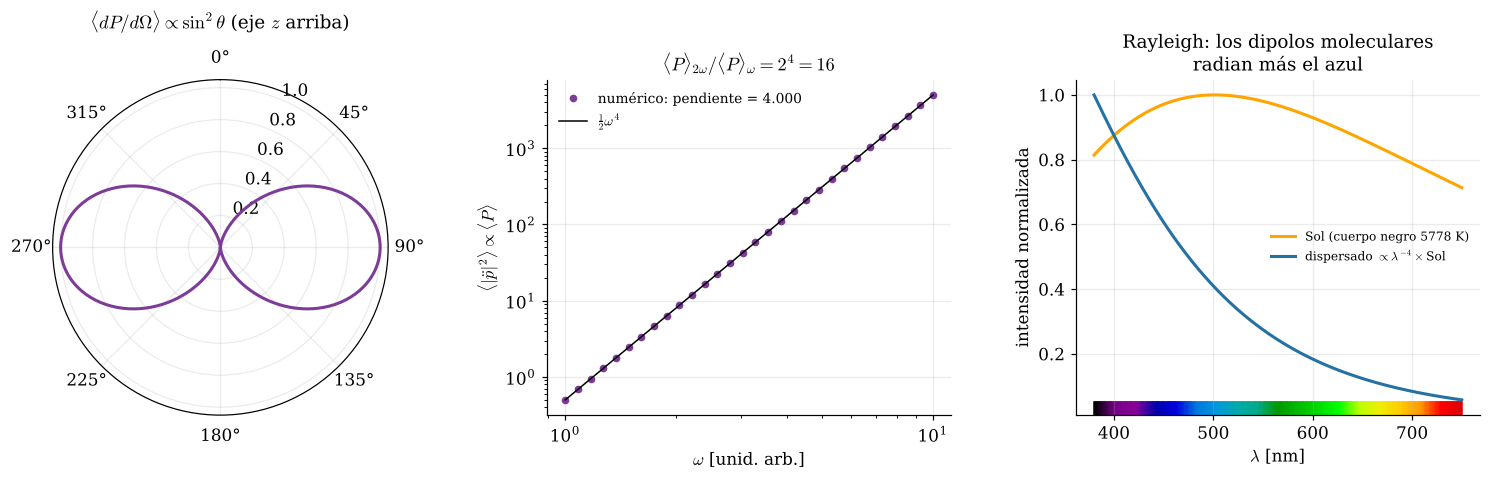

In [11]:
# patrón angular (unidades mu0 p0^2 w^4 /(32 pi^2 c))
th = np.linspace(0, 2*np.pi, 400)
fig = plt.figure(figsize=(14, 4.4))
A = fig.add_subplot(1, 3, 1, projection='polar')
A.plot(th, np.sin(th)**2, color=C['S'], lw=2)
A.set_theta_zero_location('N'); A.set_theta_direction(-1); A.set_title(r'$\langle dP/d\Omega\rangle\propto\sin^2\theta$ (eje $z$ arriba)', pad=14)

# integral numérica: <P> en unidades de mu0 p0^2 w^4/(32 pi^2 c)
I = u.integrar_esfera(lambda n: 1 - n[..., 2]**2)
print(f"∮ sin²θ dΩ = {I:.6f} = 8π/3  ->  <P> = (8π/3)/(32π²) μ0 p0² ω⁴/c = μ0 p0² ω⁴/(12π c)  ✓")

# ley omega^4: P ∝ |p̈|^2
A = fig.add_subplot(1, 3, 2)
om = np.logspace(0, 1, 30)
P = np.array([np.mean((o**2*np.cos(o*np.linspace(0, 2*np.pi/o, 400)))**2) for o in om])  # <|p̈|^2>
pend = np.polyfit(np.log(om), np.log(P), 1)[0]
A.loglog(om, P, 'o', color=C['S'], ms=4, label=f'numérico: pendiente = {pend:.3f}')
A.loglog(om, 0.5*om**4, 'k-', lw=1, label=r'$\frac{1}{2}\omega^4$')
A.set_xlabel(r'$\omega$ [unid. arb.]'); A.set_ylabel(r'$\langle|\ddot p|^2\rangle\propto\langle P\rangle$')
A.set_title(r'$\langle P\rangle_{2\omega}/\langle P\rangle_\omega=2^4=16$'); A.legend(fontsize=9)

# aplicación: el cielo azul (Rayleigh)
A = fig.add_subplot(1, 3, 3)
lam = np.linspace(380e-9, 750e-9, 300)
h, cl, kB, Ts = 6.626e-34, 2.998e8, 1.381e-23, 5778
planck = 1/lam**5/(np.exp(h*cl/(lam*kB*Ts)) - 1)
disp = planck*lam**-4
for i in range(len(lam) - 1):
    A.axvspan(lam[i]*1e9, lam[i + 1]*1e9, ymin=0, ymax=0.04,
              color=plt.cm.nipy_spectral((lam[i] - 380e-9)/(750e-9 - 380e-9)*0.9))
A.plot(lam*1e9, planck/planck.max(), color='orange', lw=2, label='Sol (cuerpo negro 5778 K)')
A.plot(lam*1e9, disp/disp.max(), color=C['B'], lw=2, label=r'dispersado $\propto\lambda^{-4}\times$Sol')
A.set_xlabel(r'$\lambda$ [nm]'); A.set_ylabel('intensidad normalizada')
A.set_title('Rayleigh: los dipolos moleculares\nradian más el azul'); A.legend(fontsize=8, loc='center right')
fig.tight_layout(); u.guardar(fig, 'P3_potencia_omega4_rayleigh'); plt.show()

---
## Problema 4 — Radiación relativista: la dirección de la aceleración importa

La potencia total (Liénard) es $P=\frac{q^2\gamma^6}{6\pi\varepsilon_0c^3}\big[a^2-|\boldsymbol\beta\times\mathbf{a}|^2\big]$. Para ver *de dónde* salen $\gamma^6$ y $\gamma^4$, miramos la distribución angular de la potencia emitida **por unidad de tiempo retardado**,

$$\frac{dP(t_r)}{d\Omega}=\frac{q^2}{16\pi^2\varepsilon_0c^3}\,\frac{\big|\hat{n}\times[(\hat{n}-\boldsymbol\beta)\times\mathbf{a}]\big|^2}{(1-\hat{n}\cdot\boldsymbol\beta)^5},$$

y la integramos numéricamente sobre la esfera. El factor $(1-\hat{n}\cdot\boldsymbol\beta)^{-5}$ concentra la emisión hacia adelante: es el **efecto faro**.

- $\mathbf{a}\parallel\mathbf{v}$ (acelerador lineal, *bremsstrahlung*): $\;dP/d\Omega\propto\sin^2\theta/(1-\beta\cos\theta)^5$.
- $\mathbf{a}\perp\mathbf{v}$ (sincrotrón): aparecen ceros en $\cos\theta=\beta$ dentro del plano $(\mathbf{v},\mathbf{a})$.

[guardado] figuras/P4_distribucion_angular_relativista.png


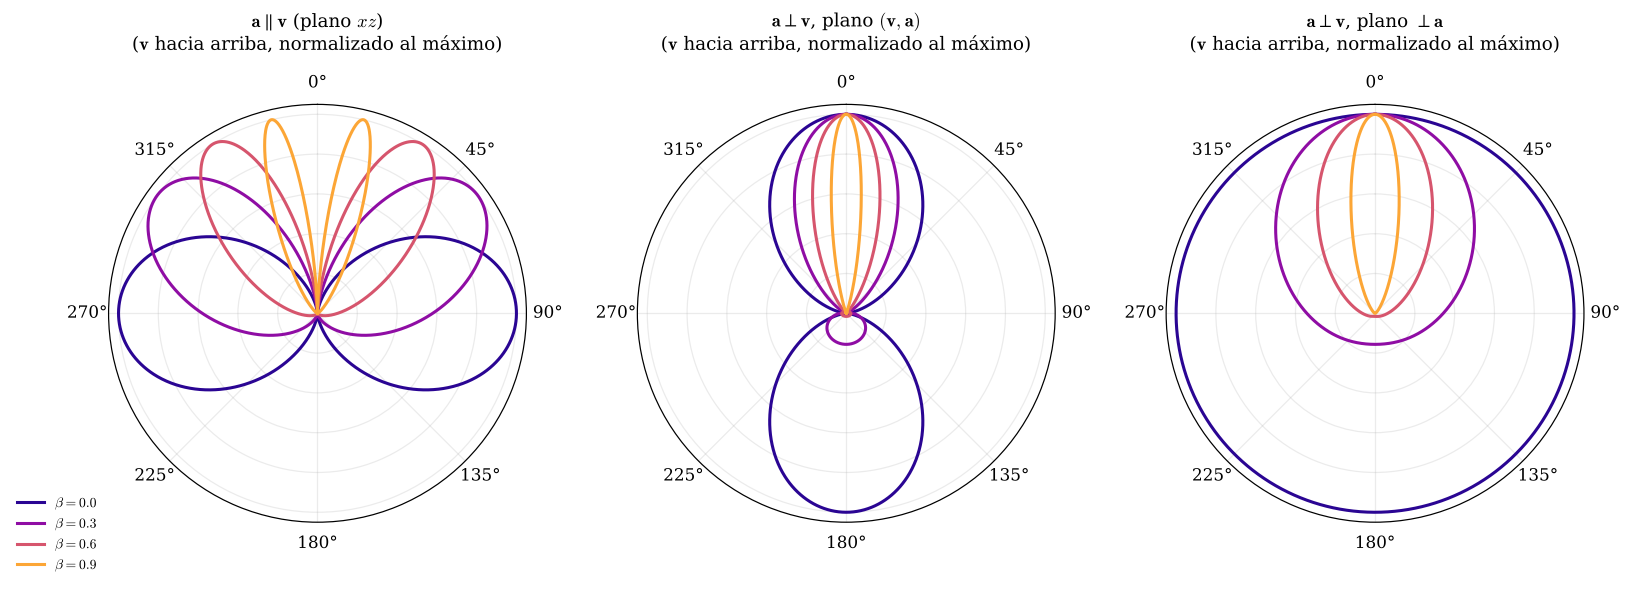

In [12]:
betas = [0.0, 0.3, 0.6, 0.9]
cols = plt.cm.plasma(np.linspace(0.05, 0.8, len(betas)))
ang = np.linspace(0, 2*np.pi, 2000)

def corte(plano, beta, a):
    # plano 'xz': n=(sin, 0, cos);  plano 'yz': n=(0, sin, cos); v siempre en +z
    if plano == 'xz':
        n = np.stack([np.sin(ang), 0*ang, np.cos(ang)], -1)
    else:
        n = np.stack([0*ang, np.sin(ang), np.cos(ang)], -1)
    return u.dPdOmega_lienard(n, [0, 0, beta], a)

casos = [('xz', [0, 0, 1], r'$\mathbf{a}\parallel\mathbf{v}$ (plano $xz$)'),
         ('xz', [1, 0, 0], r'$\mathbf{a}\perp\mathbf{v}$, plano $(\mathbf{v},\mathbf{a})$'),
         ('yz', [1, 0, 0], r'$\mathbf{a}\perp\mathbf{v}$, plano $\perp\mathbf{a}$')]
fig, ax = plt.subplots(1, 3, figsize=(15, 5), subplot_kw={'projection': 'polar'})
for A, (pl, a, tit) in zip(ax, casos):
    for be, co in zip(betas, cols):
        f = corte(pl, be, a)
        A.plot(ang, f/f.max(), color=co, lw=2, label=fr'$\beta={be}$')
    A.set_theta_zero_location('N'); A.set_theta_direction(-1); A.set_title(tit + '\n($\\mathbf{v}$ hacia arriba, normalizado al máximo)', pad=16)
    A.set_yticklabels([])
ax[0].legend(loc='lower left', bbox_to_anchor=(-0.25, -0.15), fontsize=9)
fig.tight_layout(); u.guardar(fig, 'P4_distribucion_angular_relativista'); plt.show()

In [13]:
print(" beta |  P_par/P_L   gamma^6  |  P_perp/P_L  gamma^4  | cociente  gamma^2")
lista_b = np.array([0.0, 0.3, 0.6, 0.8, 0.9, 0.95])
for be in lista_b:
    g = 1/np.sqrt(1 - be**2)
    Ppar = u.integrar_esfera(lambda n: u.dPdOmega_lienard(n, [0, 0, be], [0, 0, 1]), nmu=3000)/(8*np.pi/3)
    Pper = u.integrar_esfera(lambda n: u.dPdOmega_lienard(n, [0, 0, be], [1, 0, 0]), nmu=3000)/(8*np.pi/3)
    print(f" {be:4.2f} | {Ppar:10.4f} {g**6:9.4f} | {Pper:10.4f} {g**4:8.4f} | {Ppar/Pper:8.5f} {g**2:8.5f}")
print("\nβ = 3/5:  P_par/P_perp = 25/16 =", 25/16)

 beta |  P_par/P_L   gamma^6  |  P_perp/P_L  gamma^4  | cociente  gamma^2


 0.00 |     1.0000    1.0000 |     1.0000   1.0000 |  1.00000  1.00000


 0.30 |     1.3270    1.3270 |     1.2076   1.2076 |  1.09890  1.09890


 0.60 |     3.8147    3.8147 |     2.4414   2.4414 |  1.56250  1.56250


 0.80 |    21.4335   21.4335 |     7.7160   7.7160 |  2.77778  2.77778


 0.90 |   145.7938  145.7938 |    27.7008  27.7008 |  5.26316  5.26316


 0.95 |  1078.9123 1078.9123 |   105.1940 105.1940 | 10.25641 10.25641

β = 3/5:  P_par/P_perp = 25/16 = 1.5625


[guardado] figuras/P4_cociente_potencias_y_faro.png


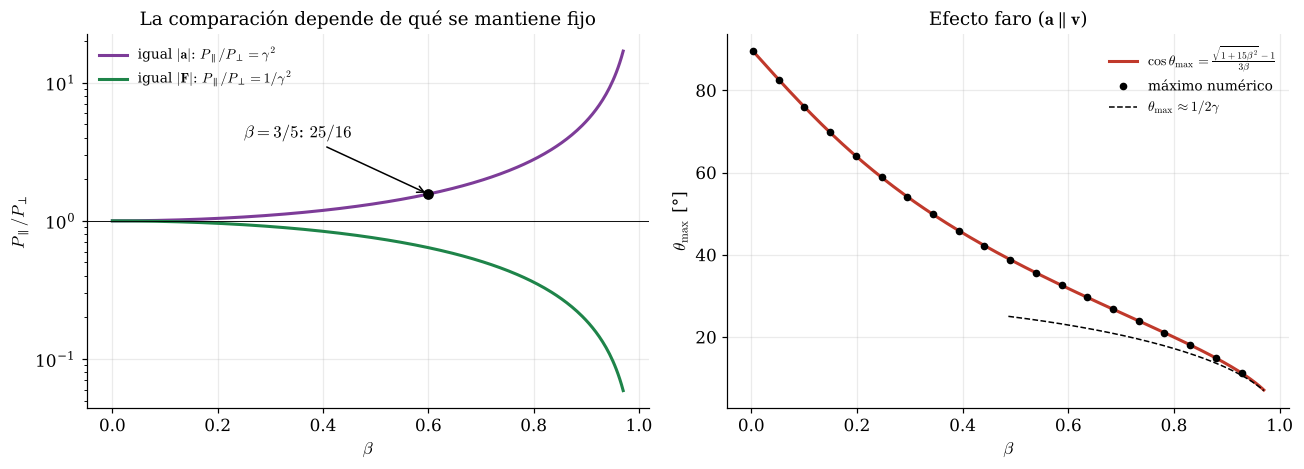

In [14]:
bb = np.linspace(0, 0.97, 300); gg = 1/np.sqrt(1 - bb**2)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
A = ax[0]
A.semilogy(bb, gg**2, color=C['S'], lw=2, label=r'igual $|\mathbf{a}|$: $P_\parallel/P_\perp=\gamma^2$')
A.semilogy(bb, gg**-2, color=C['v'], lw=2, label=r'igual $|\mathbf{F}|$: $P_\parallel/P_\perp=1/\gamma^2$')
A.plot(0.6, 25/16, 'o', color='k'); A.annotate(r'$\beta=3/5$: $25/16$', (0.6, 25/16), (0.25, 4), arrowprops=dict(arrowstyle='->'))
A.axhline(1, color='k', lw=0.6); A.set_xlabel(r'$\beta$'); A.set_ylabel(r'$P_\parallel/P_\perp$')
A.set_title('La comparación depende de qué se mantiene fijo'); A.legend(fontsize=9)

A = ax[1]
th_max_an = np.arccos((np.sqrt(1 + 15*bb[1:]**2) - 1)/(3*bb[1:]))
thg = np.linspace(1e-4, np.pi/2, 20000)
th_max_num = [thg[np.argmax(np.sin(thg)**2/(1 - be*np.cos(thg))**5)] for be in bb[1:]]
A.plot(bb[1:], np.degrees(th_max_an), color=C['E'], lw=2, label=r'$\cos\theta_{\max}=\frac{\sqrt{1+15\beta^2}-1}{3\beta}$')
A.plot(bb[1::15], np.degrees(th_max_num)[::15], 'ko', ms=4, label='máximo numérico')
A.plot(bb[150:], np.degrees(1/(2*gg[150:])), 'k--', lw=1, label=r'$\theta_{\max}\approx 1/2\gamma$')
A.set_xlabel(r'$\beta$'); A.set_ylabel(r'$\theta_{\max}$ [°]'); A.set_title(r'Efecto faro ($\mathbf{a}\parallel\mathbf{v}$)')
A.legend(fontsize=9)
fig.tight_layout(); u.guardar(fig, 'P4_cociente_potencias_y_faro'); plt.show()

**Conclusiones del Problema 4.**

1. La integración numérica reproduce $P_\parallel=\gamma^6P_L$ y $P_\perp=\gamma^4P_L$, con $P_L=q^2a^2/6\pi\varepsilon_0c^3$ (Larmor). Para $\beta=3/5$, el cociente es $25/16$.
2. Con $\beta\to0$ los tres patrones se vuelven la dona $\sin^2$ de Larmor y la dirección relativa de $\mathbf{a}$ y $\mathbf{v}$ deja de importar.
3. A igual **fuerza** el resultado se invierte, porque $a_\parallel=F/\gamma^3m$ y $a_\perp=F/\gamma m$. Por eso los electrones en un anillo de almacenamiento pierden mucha más energía que en un linac: la radiación sincrotrón es la limitación fundamental de los aceleradores circulares de leptones.
4. El efecto faro concentra la emisión en un cono de ángulo $\sim1/\gamma$.